Setup, Data Loading & Overview KPIs

=== OVERVIEW METRICS (DASHBOARD PAGE 1) ===
Snapshot Date           : 2024-02-29
Total Invoices          : 2,500,000
Total Billed Amount     : 85,098,196,047.03
Open Invoices Count     : 425,590
Outstanding Amount      : 14,484,996,299.18
Past-Due Open Invoices  : 425,571 (14,484,252,895.56)
Historical Late Rate    : 0.00%

=== UNIVARIATE SUMMARY STATISTICS ===
                  count          mean           std    min         5%        25%       50%         75%        95%        max
total_amount  2500000.0  34039.278419  29915.983566   4.52  1568.2095  9495.6275  25432.81  51612.0175  94913.114  159946.84
days_to_pay   2074410.0     17.707080     13.809632   0.00     1.0000     7.0000     15.00     27.0000     45.000      60.00
delay         2074410.0    -12.307469     12.418023 -60.00   -38.0000   -19.0000     -9.00     -2.0000      0.000       0.00 



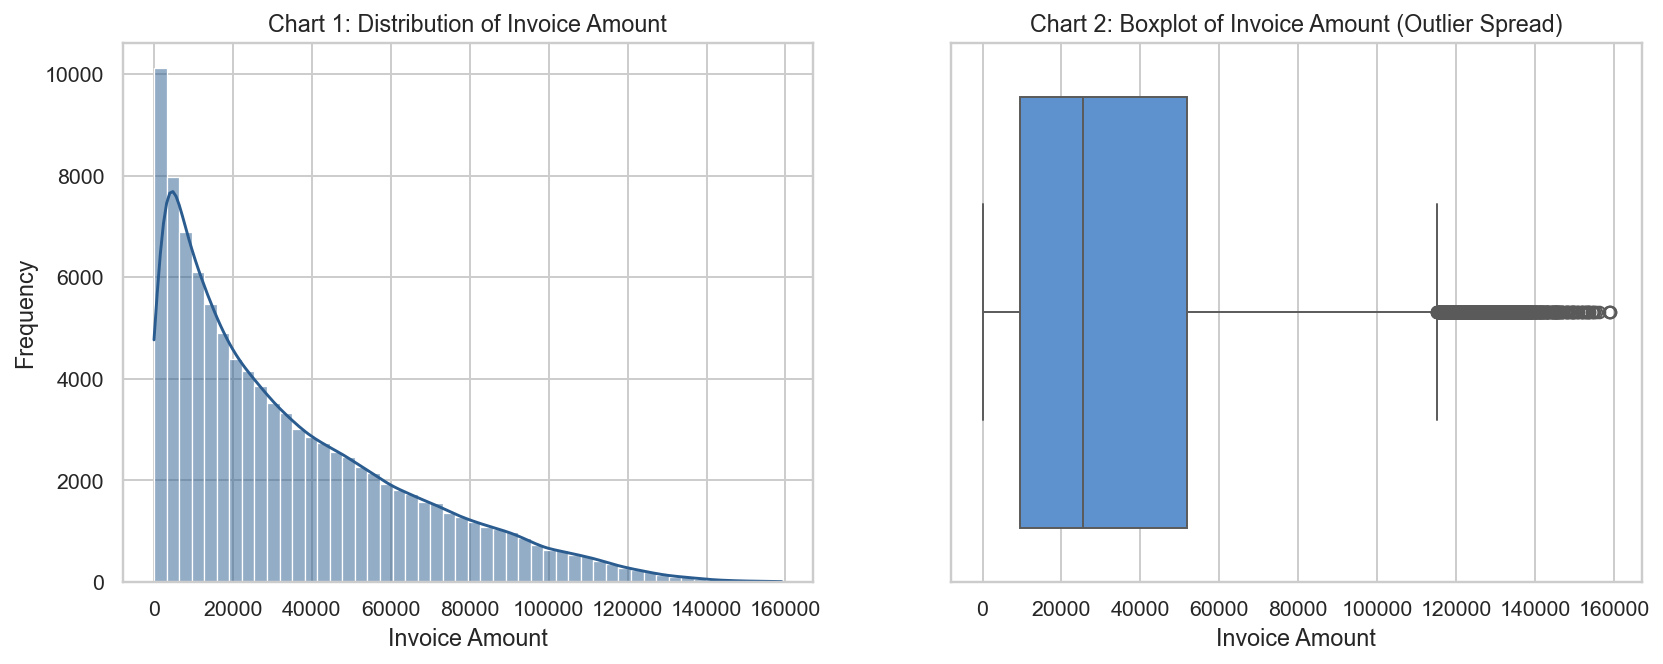

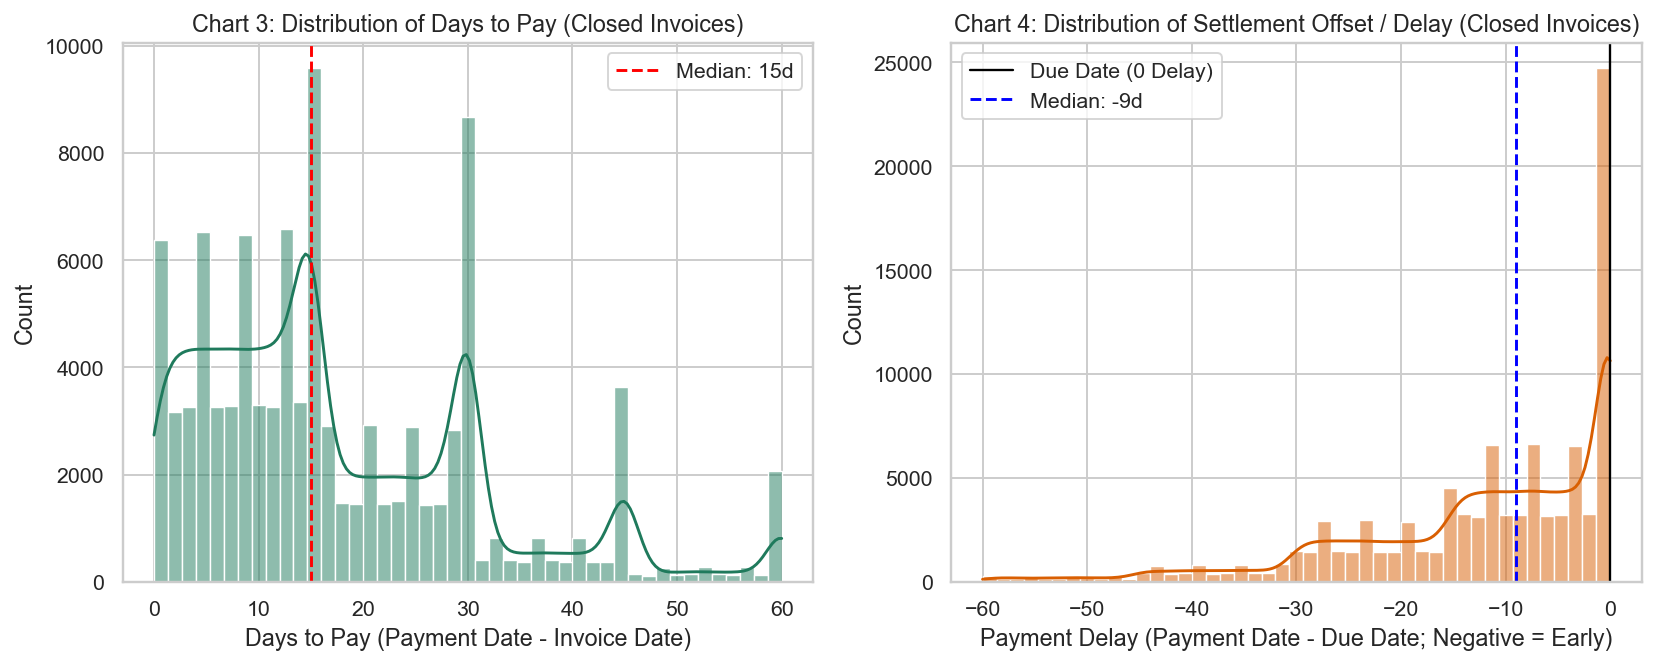

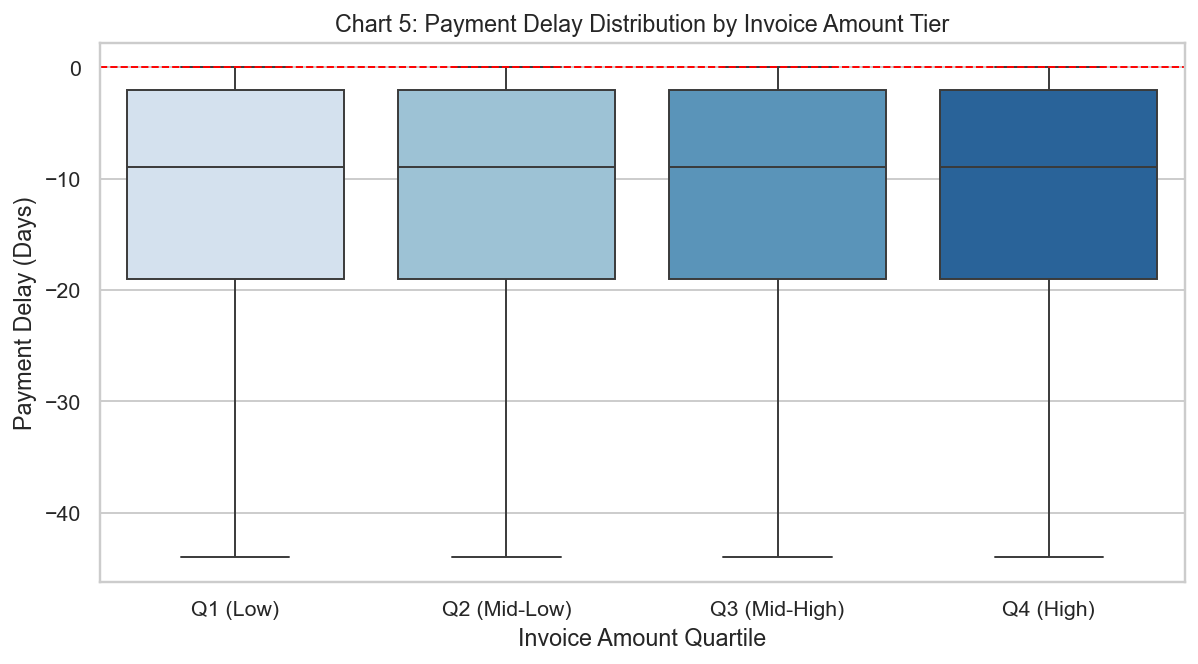

=== TOP 10 COUNTRIES BY OVERDUE SHARE ===
customer_country  mean_delay  open_rate  volume
             UAE  -12.306110  17.241175   84304
         Germany  -12.276875  17.170228  162112
           Japan  -12.298883  17.119600   85259
              UK  -12.344484  17.066681  254449
           India  -12.323812  17.044811  829578
       Singapore  -12.263362  17.003783   82217
       Australia  -12.294018  16.956239  164783
             USA  -12.294587  16.947077  670564
          Canada  -12.291419  16.934758  166734 



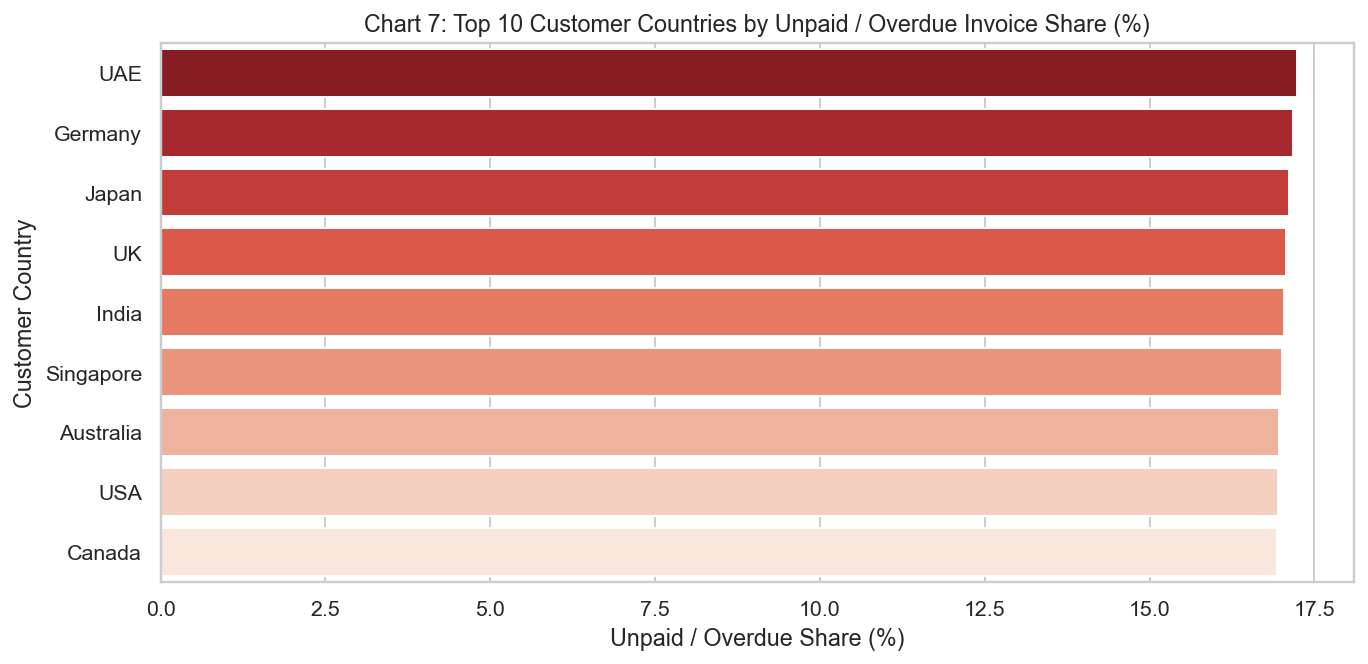

=== MONTHLY TREND (FIRST & LAST 5 MONTHS) ===
invoice_month  invoice_count  mean_delay  open_rate
      2019-01          42363  -12.364580  17.227297
      2019-02          38397  -12.324199  16.647134
      2019-03          42420  -12.227225  17.065064
      2019-04          41092  -12.333539  17.005743
      2019-05          42246  -12.245540  17.199261
      2023-08          42475  -12.332642  17.191289
      2023-09          41067  -12.194502  16.996615
      2023-10          42091  -12.293888  17.243591
      2023-11          41216  -12.275621  16.998253
      2023-12          42531  -12.308567  17.309727 



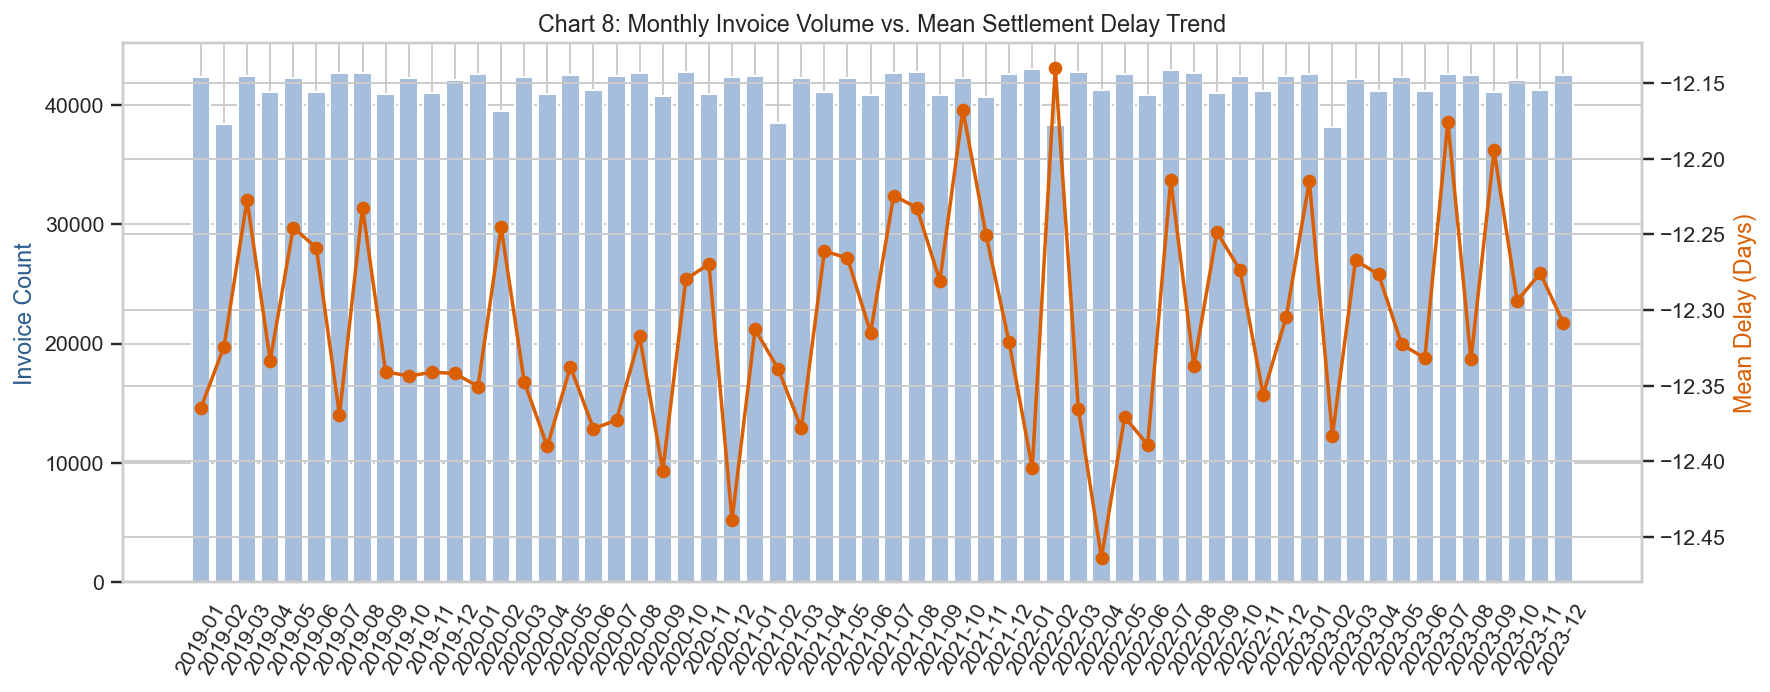

=== PERIOD-END EFFECT ===
Period Type  Mean Delay (Days)
Regular Day         -12.307682
  Month-End         -12.301209
Quarter-End         -12.263953 



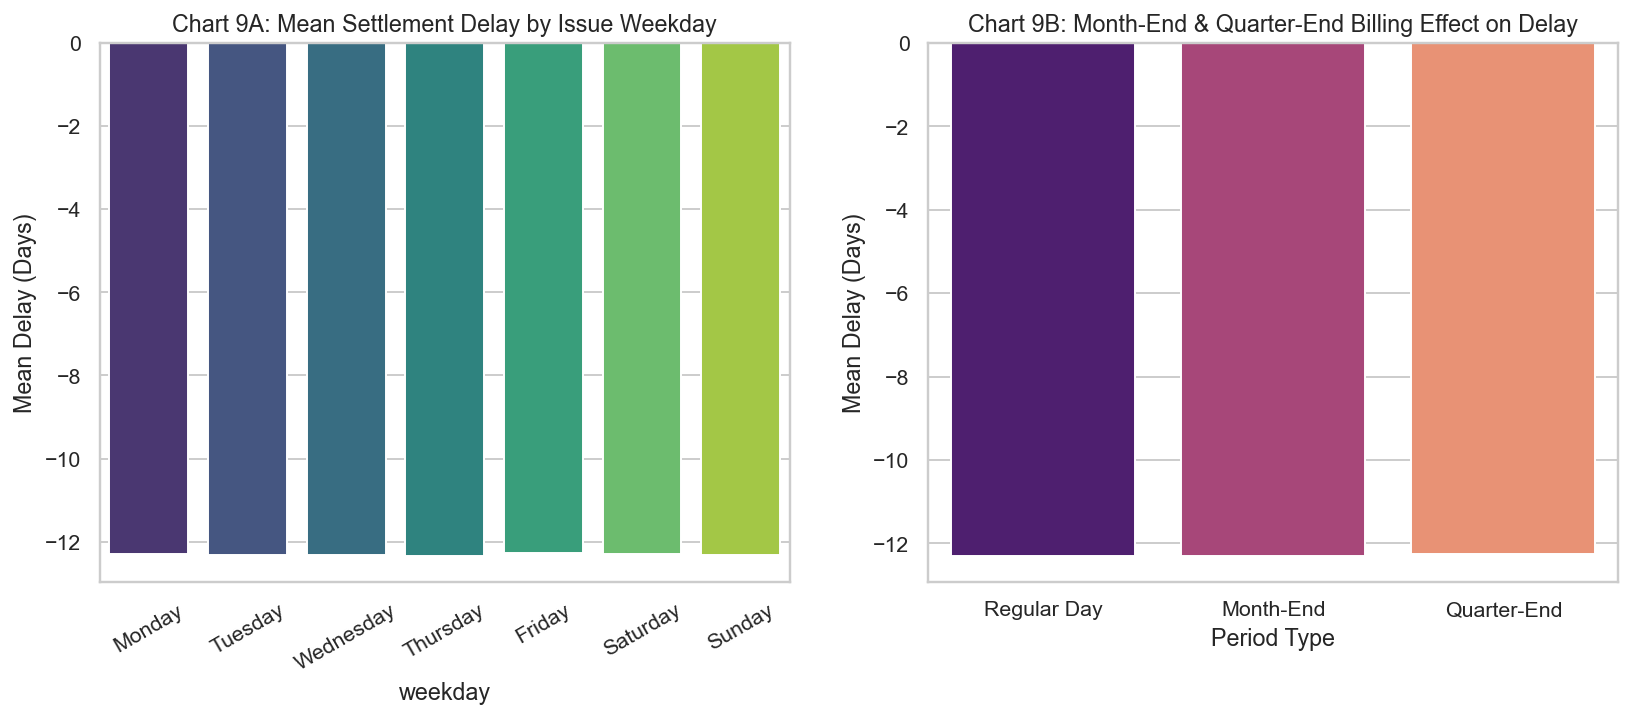

=== TOP 10 HIGH-RISK CUSTOMERS ===
      customer_name  total_invoices  total_spend  mean_delay  open_unpaid_count  unpaid_rate
         Sarah Park            1757  60578557.94  -12.542674                351    19.977234
Elizabeth Rodriguez            1343  47257705.31  -11.872677                267    19.880864
         Nisha Nair            1553  54217897.29  -11.841767                308    19.832582
          Wei Zhang            1436  51213851.24  -12.529514                284    19.777159
      Jessica Zhang            1487  50869016.77  -12.383906                294    19.771352
         Chen Jones            1771  61176655.84  -12.071730                349    19.706381
     Jessica Miller            1780  60921988.86  -11.828671                350    19.662921
       Ishaan Kumar            1644  55593460.77  -12.267020                322    19.586375
        James Patel            1617  52773265.57  -12.521906                316    19.542362
      Michael Davis            1524

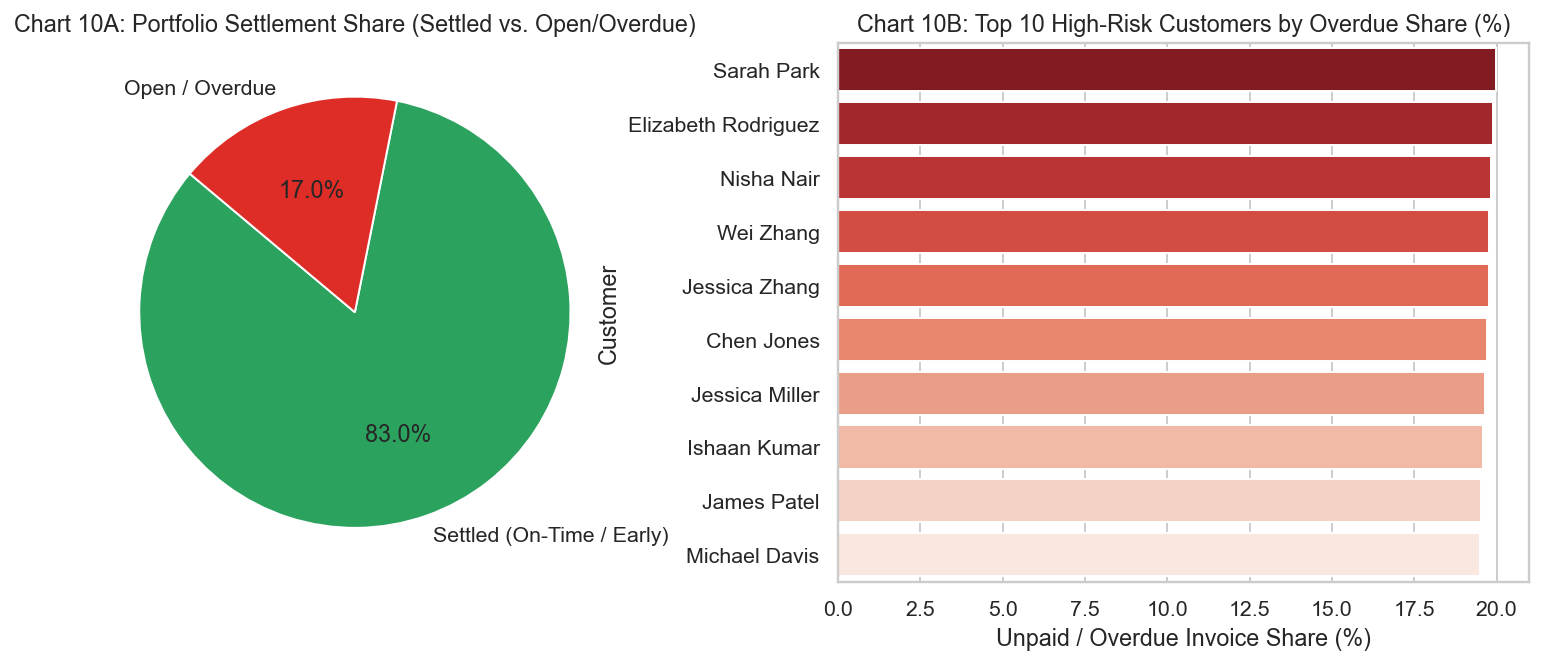

=== REPEAT CUSTOMER TIERS ===
   frequency_tier  customer_count  avg_unpaid_rate  avg_delay
     One-Time (1)               0              NaN        NaN
 Occasional (2-5)               0              NaN        NaN
   Regular (6-20)               0              NaN        NaN
High-Volume (20+)            1500        17.019044 -12.308637 



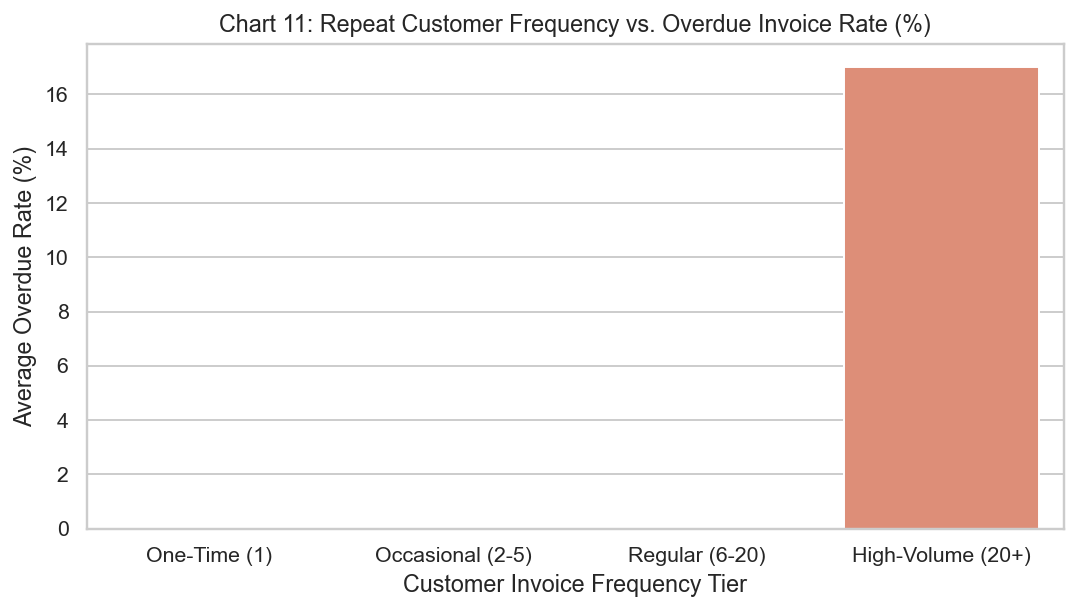

=== AGING BUCKET SUMMARY ===
aging_bucket  invoice_count  outstanding_value
   0-30 Days           1375       4.646344e+07
  31-60 Days           5946       2.031187e+08
  61-90 Days           6969       2.380722e+08
    90+ Days         411281       1.399660e+10 



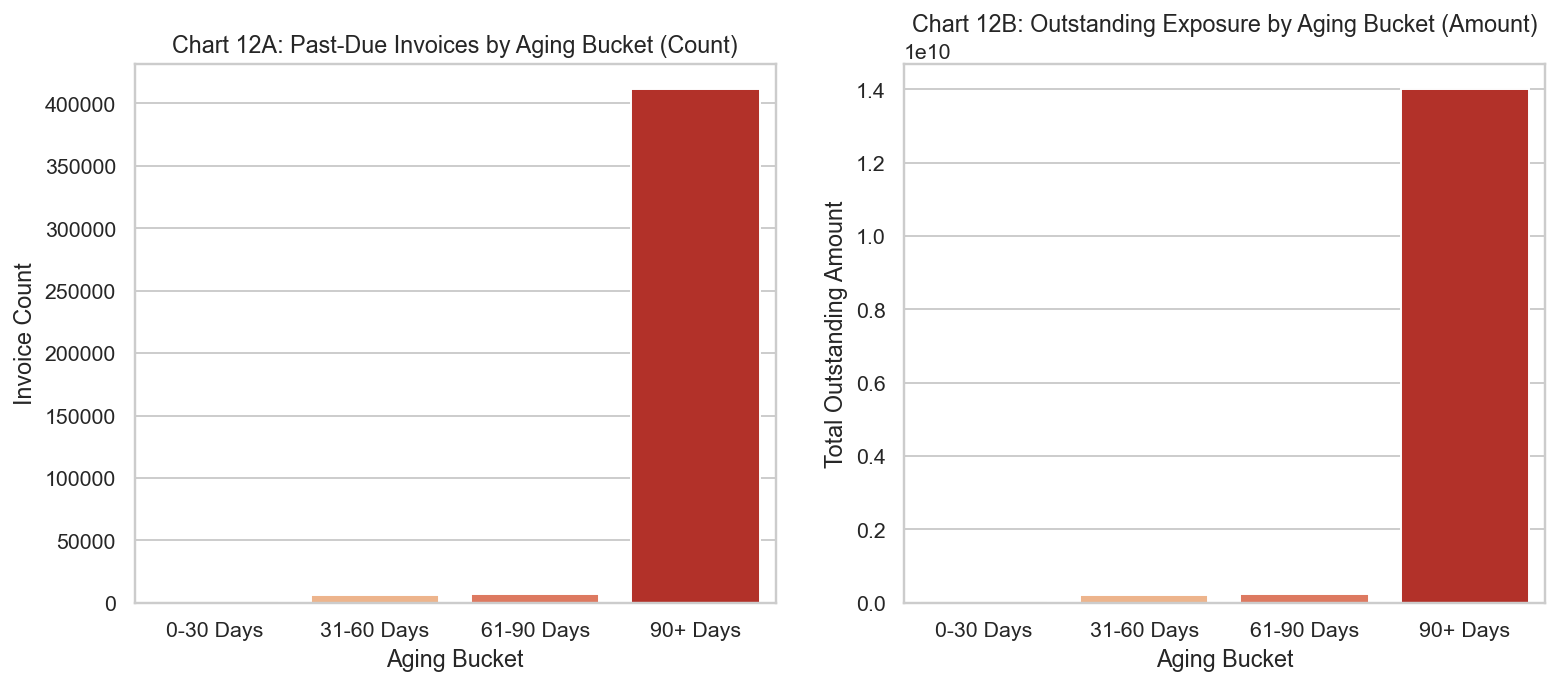

=== CORRELATION MATRIX ===
                      total_amount  tax_amount  credit_window_days  days_to_pay  delay  open_paid_flag  invoice_day_of_month  invoice_month_num
total_amount                 1.000       0.860              -0.001       -0.001  0.001          -0.000                -0.001             -0.000
tax_amount                   0.860       1.000              -0.001       -0.001  0.001          -0.000                -0.001              0.000
credit_window_days          -0.001      -0.001               1.000        0.608 -0.470          -0.000                -0.001             -0.000
days_to_pay                 -0.001      -0.001               0.608        1.000  0.415             NaN                -0.001              0.001
delay                        0.001       0.001              -0.470        0.415  1.000             NaN                 0.000              0.000
open_paid_flag              -0.000      -0.000              -0.000          NaN    NaN           1.000       

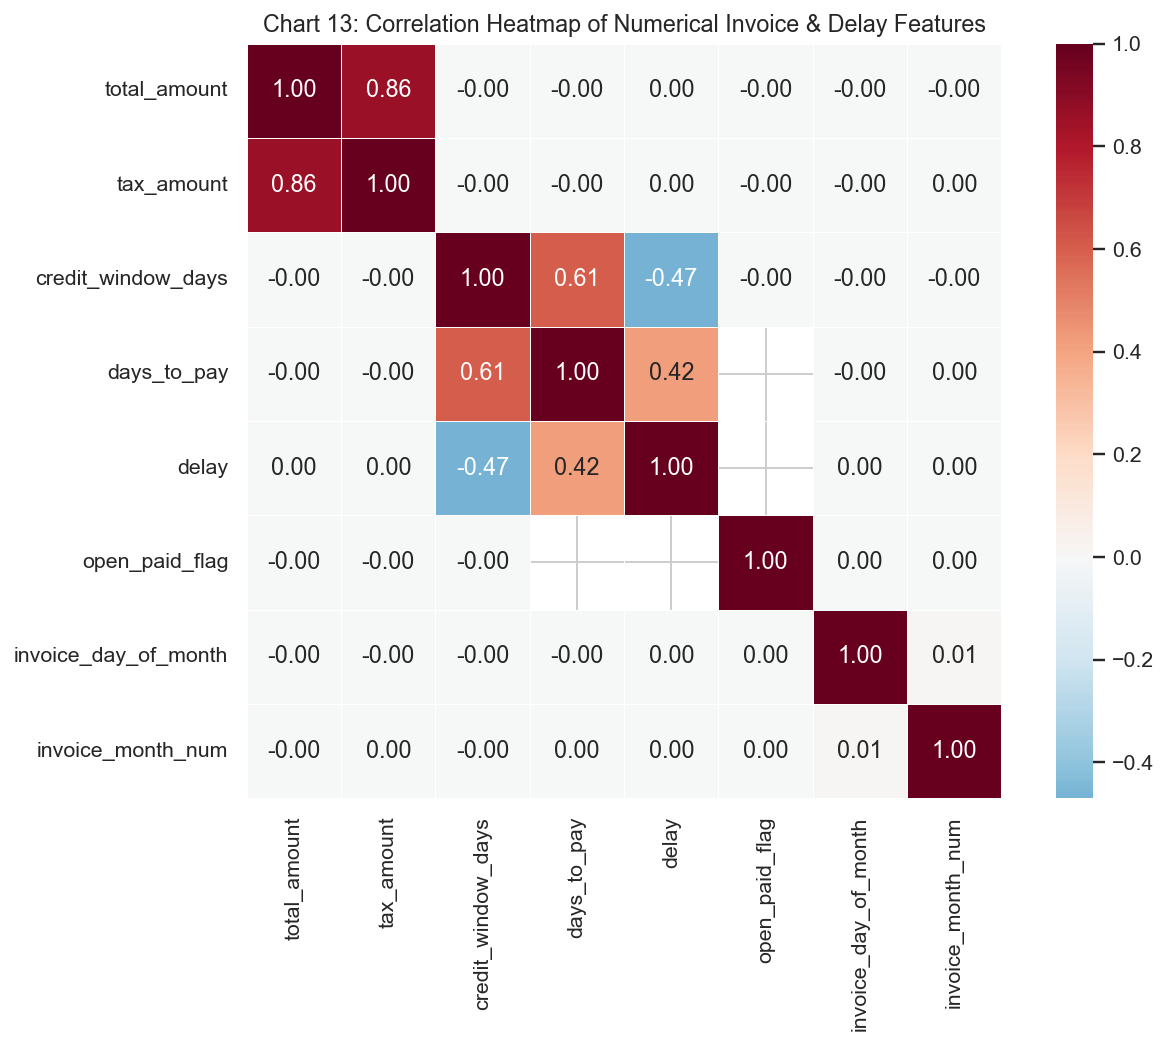

In [6]:
import gc
import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns

# Suppress non-fatal Seaborn deprecation warnings
warnings.filterwarnings("ignore")

# Create output directory for figures
os.makedirs("../reports/figures", exist_ok=True)

# Configure visual styling
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 140
plt.rcParams["savefig.bbox"] = "tight"

# ------------------------------------------------------------------------------
# 1. DATA LOADING & OVERVIEW METRICS (TASK 5)
# ------------------------------------------------------------------------------
parquet_path = "../data/processed/cleaned_invoices.parquet"
cols_needed = [
    "invoice_id", "customer_id", "customer_name", "customer_country",
    "invoice_date", "due_date", "payment_date", "payment_terms",
    "total_amount", "tax_amount", "currency", "payment_status",
    "open_paid_flag", "days_to_pay", "delay", "paid_late_flag",
]
available_cols = pq.read_schema(parquet_path).names
use_cols = [c for c in cols_needed if c in available_cols]

df = pd.read_parquet(parquet_path, columns=use_cols)
gc.collect()

for col in ["invoice_date", "due_date", "payment_date"]:
    df[col] = pd.to_datetime(df[col])

closed_mask = df["open_paid_flag"] == 0
open_mask = df["open_paid_flag"] == 1

# Re-verify paid_late_flag directly from delay > 0 on closed invoices
df["paid_late_flag"] = np.where(
    df["open_paid_flag"] == 1,
    np.nan,
    (df["delay"] > 0).astype(float)
)

snapshot_date = df[["invoice_date", "due_date", "payment_date"]].max().max()
open_days_past_due = (snapshot_date - df.loc[open_mask, "due_date"]).dt.days

total_invoices = len(df)
total_billed = df["total_amount"].sum()
outstanding_amount = df.loc[open_mask, "total_amount"].sum()
past_due_mask = open_mask & ((snapshot_date - df["due_date"]).dt.days > 0)
past_due_count = past_due_mask.sum()
past_due_amount = df.loc[past_due_mask, "total_amount"].sum()
historical_late_rate = df.loc[closed_mask, "paid_late_flag"].mean() * 100

print("=== OVERVIEW METRICS (DASHBOARD PAGE 1) ===")
print(f"Snapshot Date           : {snapshot_date.date()}")
print(f"Total Invoices          : {total_invoices:,}")
print(f"Total Billed Amount     : {total_billed:,.2f}")
print(f"Open Invoices Count     : {open_mask.sum():,}")
print(f"Outstanding Amount      : {outstanding_amount:,.2f}")
print(f"Past-Due Open Invoices  : {past_due_count:,} ({past_due_amount:,.2f})")
print(f"Historical Late Rate    : {historical_late_rate:.2f}%\n")

# ------------------------------------------------------------------------------
# 2. UNIVARIATE ANALYSIS: AMOUNT, DAYS TO PAY & DELAY (TASK 1 | CHARTS 1-4)
# ------------------------------------------------------------------------------
summary_stats = df[["total_amount", "days_to_pay", "delay"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
).T
print("=== UNIVARIATE SUMMARY STATISTICS ===")
print(summary_stats.to_string(), "\n")

sample_all = df.sample(100000, random_state=42)
sample_closed = df.loc[closed_mask].sample(100000, random_state=42)

# Charts 1 & 2: Invoice Amount Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(sample_all["total_amount"], bins=50, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Chart 1: Distribution of Invoice Amount")
axes[0].set_xlabel("Invoice Amount")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=sample_all["total_amount"], ax=axes[1], color="#4a90e2")
axes[1].set_title("Chart 2: Boxplot of Invoice Amount (Outlier Spread)")
axes[1].set_xlabel("Invoice Amount")
plt.savefig("../reports/figures/fig01_02_invoice_amount_univariate.png")
plt.show()

# Charts 3 & 4: Days to Pay & Payment Delay Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(sample_closed["days_to_pay"], bins=45, kde=True, ax=axes[0], color="#1f7a5c")
axes[0].axvline(
    df.loc[closed_mask, "days_to_pay"].median(), color="red", linestyle="--",
    label=f"Median: {df.loc[closed_mask, 'days_to_pay'].median():.0f}d"
)
axes[0].set_title("Chart 3: Distribution of Days to Pay (Closed Invoices)")
axes[0].set_xlabel("Days to Pay (Payment Date - Invoice Date)")
axes[0].legend()

sns.histplot(sample_closed["delay"], bins=45, kde=True, ax=axes[1], color="#d95f02")
axes[1].axvline(0, color="black", linestyle="-", linewidth=1.2, label="Due Date (0 Delay)")
axes[1].axvline(
    df.loc[closed_mask, "delay"].median(), color="blue", linestyle="--",
    label=f"Median: {df.loc[closed_mask, 'delay'].median():.0f}d"
)
axes[1].set_title("Chart 4: Distribution of Settlement Offset / Delay (Closed Invoices)")
axes[1].set_xlabel("Payment Delay (Payment Date - Due Date; Negative = Early)")
axes[1].legend()
plt.savefig("../reports/figures/fig03_04_turnaround_and_delay.png")
plt.show()

# ------------------------------------------------------------------------------
# 3. BIVARIATE ANALYSIS: AMOUNT TIER, TERMS & COUNTRY (TASK 2 | CHARTS 5-7)
# ------------------------------------------------------------------------------
df["amount_tier"] = pd.qcut(
    df["total_amount"], q=4, labels=["Q1 (Low)", "Q2 (Mid-Low)", "Q3 (Mid-High)", "Q4 (High)"]
)

# Chart 5: Payment Delay across Invoice Amount Tiers
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df.loc[closed_mask].sample(120000, random_state=42),
    x="amount_tier", y="delay", hue="amount_tier",
    showfliers=False, palette="Blues", legend=False
)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title("Chart 5: Payment Delay Distribution by Invoice Amount Tier")
plt.xlabel("Invoice Amount Quartile")
plt.ylabel("Payment Delay (Days)")
plt.savefig("../reports/figures/fig05_delay_by_amount_tier.png")
plt.show()

# Chart 6: Mean Delay & Delinquency Rate by Payment Terms (if column exists)
term_col = next((c for c in df.columns if "term" in c.lower()), None)
if term_col:
    term_summary = df.groupby(term_col, observed=False).agg(
        mean_delay=("delay", "mean"),
        open_delinquency_rate=("open_paid_flag", lambda x: x.mean() * 100),
        count=("invoice_id", "count")
    ).reset_index().sort_values("mean_delay", ascending=False)
    print("=== PAYMENT TERMS SUMMARY ===")
    print(term_summary.to_string(index=False), "\n")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(data=term_summary, x=term_col, y="mean_delay", hue=term_col, ax=axes[0], palette="Blues_d", legend=False)
    axes[0].set_title("Chart 6A: Mean Settlement Delay by Payment Terms")
    axes[0].set_ylabel("Mean Delay (Days)")
    axes[0].tick_params(axis="x", rotation=30)

    sns.barplot(data=term_summary, x=term_col, y="open_delinquency_rate", hue=term_col, ax=axes[1], palette="Reds_d", legend=False)
    axes[1].set_title("Chart 6B: Unpaid / Overdue Share (%) by Payment Terms")
    axes[1].set_ylabel("Unpaid Invoice Rate (%)")
    axes[1].tick_params(axis="x", rotation=30)
    plt.savefig("../reports/figures/fig06_delay_by_terms.png")
    plt.show()

# Chart 7: Top 10 Countries by Unpaid / Overdue Share
if "customer_country" in df.columns:
    country_summary = df.groupby("customer_country").agg(
        mean_delay=("delay", "mean"),
        open_rate=("open_paid_flag", lambda x: x.mean() * 100),
        volume=("invoice_id", "count")
    ).reset_index().sort_values("open_rate", ascending=False).head(10)
    print("=== TOP 10 COUNTRIES BY OVERDUE SHARE ===")
    print(country_summary.to_string(index=False), "\n")

    plt.figure(figsize=(11, 5))
    sns.barplot(data=country_summary, x="open_rate", y="customer_country", hue="customer_country", palette="Reds_r", legend=False)
    plt.title("Chart 7: Top 10 Customer Countries by Unpaid / Overdue Invoice Share (%)")
    plt.xlabel("Unpaid / Overdue Share (%)")
    plt.ylabel("Customer Country")
    plt.savefig("../reports/figures/fig07_delay_by_country.png")
    plt.show()

# ------------------------------------------------------------------------------
# 4. TIME, SEASONALITY & PERIOD-END EFFECTS (TASKS 2 & 3 | CHARTS 8-9)
# ------------------------------------------------------------------------------
df["invoice_month"] = df["invoice_date"].dt.to_period("M").astype(str)
df["weekday"] = df["invoice_date"].dt.day_name()
df["is_month_end"] = df["invoice_date"].dt.is_month_end
df["is_quarter_end"] = df["invoice_date"].dt.is_quarter_end

# Chart 8: Monthly Invoice Volume & Mean Delay Trend
monthly_trend = df.groupby("invoice_month").agg(
    invoice_count=("invoice_id", "count"),
    mean_delay=("delay", "mean"),
    open_rate=("open_paid_flag", lambda x: x.mean() * 100)
).reset_index().sort_values("invoice_month")
print("=== MONTHLY TREND (FIRST & LAST 5 MONTHS) ===")
print(pd.concat([monthly_trend.head(5), monthly_trend.tail(5)]).to_string(index=False), "\n")

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(monthly_trend["invoice_month"], monthly_trend["invoice_count"], color="#a6bddb", label="Invoice Volume")
ax1.set_ylabel("Invoice Count", color="#2b5c8f")
ax1.tick_params(axis="x", rotation=60)

ax2 = ax1.twinx()
ax2.plot(monthly_trend["invoice_month"], monthly_trend["mean_delay"], color="#d95f02", marker="o", linewidth=1.8)
ax2.set_ylabel("Mean Delay (Days)", color="#d95f02")
plt.title("Chart 8: Monthly Invoice Volume vs. Mean Settlement Delay Trend")
plt.savefig("../reports/figures/fig08_monthly_volume_and_delay.png")
plt.show()

# Charts 9A & 9B: Weekday & Period-End Billing Effect
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weekday_delay = df.loc[closed_mask].groupby("weekday")["delay"].mean().reindex(weekday_order).reset_index()
sns.barplot(data=weekday_delay, x="weekday", y="delay", hue="weekday", ax=axes[0], palette="viridis", legend=False)
axes[0].set_title("Chart 9A: Mean Settlement Delay by Issue Weekday")
axes[0].set_ylabel("Mean Delay (Days)")
axes[0].tick_params(axis="x", rotation=30)

period_end_df = pd.DataFrame({
    "Period Type": ["Regular Day", "Month-End", "Quarter-End"],
    "Mean Delay (Days)": [
        df.loc[closed_mask & ~df["is_month_end"] & ~df["is_quarter_end"], "delay"].mean(),
        df.loc[closed_mask & df["is_month_end"], "delay"].mean(),
        df.loc[closed_mask & df["is_quarter_end"], "delay"].mean()
    ]
})
print("=== PERIOD-END EFFECT ===")
print(period_end_df.to_string(index=False), "\n")

sns.barplot(data=period_end_df, x="Period Type", y="Mean Delay (Days)", hue="Period Type", ax=axes[1], palette="magma", legend=False)
axes[1].set_title("Chart 9B: Month-End & Quarter-End Billing Effect on Delay")
plt.savefig("../reports/figures/fig09_weekday_and_period_end.png")
plt.show()

# ------------------------------------------------------------------------------
# 5. CUSTOMER RISK & REPEAT-CUSTOMER BEHAVIOR (TASK 4 | CHARTS 10-11)
# ------------------------------------------------------------------------------
cust_col = "customer_name" if "customer_name" in df.columns else "customer_id"
customer_stats = df.groupby(cust_col).agg(
    total_invoices=("invoice_id", "count"),
    total_spend=("total_amount", "sum"),
    mean_delay=("delay", "mean"),
    open_unpaid_count=("open_paid_flag", "sum"),
    unpaid_rate=("open_paid_flag", lambda x: x.mean() * 100)
).reset_index()

# Charts 10A & 10B: Portfolio Settlement Share & Top 10 High-Risk Customers
status_counts = df["open_paid_flag"].value_counts().rename({0: "Settled (On-Time / Early)", 1: "Open / Overdue"})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie(status_counts, labels=status_counts.index, autopct="%1.1f%%", startangle=140, colors=["#2ca25f", "#de2d26"])
axes[0].set_title("Chart 10A: Portfolio Settlement Share (Settled vs. Open/Overdue)")

top_risk_customers = customer_stats[customer_stats["total_invoices"] >= 10].sort_values(
    ["unpaid_rate", "mean_delay"], ascending=[False, False]
).head(10)
print("=== TOP 10 HIGH-RISK CUSTOMERS ===")
print(top_risk_customers.to_string(index=False), "\n")

sns.barplot(data=top_risk_customers, x="unpaid_rate", y=cust_col, hue=cust_col, ax=axes[1], palette="Reds_r", legend=False)
axes[1].set_title("Chart 10B: Top 10 High-Risk Customers by Overdue Share (%)")
axes[1].set_xlabel("Unpaid / Overdue Invoice Share (%)")
axes[1].set_ylabel("Customer")
plt.savefig("../reports/figures/fig10_customer_risk_analysis.png")
plt.show()

# Chart 11: Repeat Customer Frequency Tiers
customer_stats["frequency_tier"] = pd.cut(
    customer_stats["total_invoices"],
    bins=[0, 1, 5, 20, np.inf],
    labels=["One-Time (1)", "Occasional (2-5)", "Regular (6-20)", "High-Volume (20+)"]
)
repeat_summary = customer_stats.groupby("frequency_tier", observed=False).agg(
    customer_count=(cust_col, "count"),
    avg_unpaid_rate=("unpaid_rate", "mean"),
    avg_delay=("mean_delay", "mean")
).reset_index()
print("=== REPEAT CUSTOMER TIERS ===")
print(repeat_summary.to_string(index=False), "\n")

plt.figure(figsize=(9, 4.5))
sns.barplot(data=repeat_summary, x="frequency_tier", y="avg_unpaid_rate", hue="frequency_tier", palette="coolwarm", legend=False)
plt.title("Chart 11: Repeat Customer Frequency vs. Overdue Invoice Rate (%)")
plt.xlabel("Customer Invoice Frequency Tier")
plt.ylabel("Average Overdue Rate (%)")
plt.savefig("../reports/figures/fig11_repeat_customer_behavior.png")
plt.show()

# ------------------------------------------------------------------------------
# 6. AGING BUCKETS & CORRELATION HEATMAP (TASKS 6 & 7 | CHARTS 12-13)
# ------------------------------------------------------------------------------
overdue_mask = open_mask & (open_days_past_due > 0)
aging_buckets = pd.cut(
    open_days_past_due[overdue_mask],
    bins=[0, 30, 60, 90, np.inf],
    labels=["0-30 Days", "31-60 Days", "61-90 Days", "90+ Days"]
)
aging_summary = pd.DataFrame({
    "aging_bucket": aging_buckets,
    "total_amount": df.loc[overdue_mask, "total_amount"]
}).groupby("aging_bucket", observed=False).agg(
    invoice_count=("total_amount", "count"),
    outstanding_value=("total_amount", "sum")
).reset_index()
print("=== AGING BUCKET SUMMARY ===")
print(aging_summary.to_string(index=False), "\n")

# Charts 12A & 12B: Aging Buckets
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=aging_summary, x="aging_bucket", y="invoice_count", hue="aging_bucket", ax=axes[0], palette="OrRd", legend=False)
axes[0].set_title("Chart 12A: Past-Due Invoices by Aging Bucket (Count)")
axes[0].set_xlabel("Aging Bucket")
axes[0].set_ylabel("Invoice Count")

sns.barplot(data=aging_summary, x="aging_bucket", y="outstanding_value", hue="aging_bucket", ax=axes[1], palette="OrRd", legend=False)
axes[1].set_title("Chart 12B: Outstanding Exposure by Aging Bucket (Amount)")
axes[1].set_xlabel("Aging Bucket")
axes[1].set_ylabel("Total Outstanding Amount")
plt.savefig("../reports/figures/fig12_aging_buckets.png")
plt.show()

# Task 7: Correlation Heatmap
df["credit_window_days"] = (df["due_date"] - df["invoice_date"]).dt.days
df["invoice_day_of_month"] = df["invoice_date"].dt.day
df["invoice_month_num"] = df["invoice_date"].dt.month

num_cols = [
    c for c in [
        "total_amount", "tax_amount", "credit_window_days", "days_to_pay",
        "delay", "open_paid_flag", "invoice_day_of_month", "invoice_month_num"
    ] if c in df.columns
]
corr_matrix = df[num_cols].corr()
print("=== CORRELATION MATRIX ===")
print(corr_matrix.round(3).to_string(), "\n")

# Chart 13: Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True, linewidths=0.5)
plt.title("Chart 13: Correlation Heatmap of Numerical Invoice & Delay Features")
plt.savefig("../reports/figures/fig13_correlation_heatmap.png")
plt.show()